In [2]:
import os,re,json,time,random,gc,zipfile,copy,io,subprocess,sys,math
from pathlib import Path
from fractions import Fraction
import numpy as np,pandas as pd,torch,requests,wfdb,pyedflib
import matplotlib.pyplot as plt
from scipy.signal import resample_poly
from sklearn.metrics import confusion_matrix,accuracy_score,precision_recall_fscore_support,balanced_accuracy_score,roc_auc_score,average_precision_score,mean_absolute_error,mean_squared_error,r2_score
from torch import nn
from torch.utils.data import Dataset,DataLoader
SEED=42; EPOCHS=12; FS=128; CTX=4; HORIZON=1; LENGTH=FS*CTX; FUTURE=FS*HORIZON
BS=32; LR=2e-4; DEVICE='cuda' if torch.cuda.is_available() else 'cpu'; torch.set_num_threads(4)
ROOT=Path('/kaggle/working/nct_seizure_repair'); CACHE=ROOT/'cache'; OUT=ROOT/'output'
for p in (CACHE,OUT):p.mkdir(parents=True,exist_ok=True)
random.seed(SEED);np.random.seed(SEED);torch.manual_seed(SEED)
if torch.cuda.is_available():torch.cuda.manual_seed_all(SEED)
print('DEVICE:',DEVICE,'Torch:',torch.__version__)
assert DEVICE=='cuda','Enable Kaggle GPU T4'

DEVICE: cuda Torch: 2.11.0+cu128


In [3]:
# Discover attached Kaggle inputs / checkpoints / preprocessed caches.
import zipfile, shutil
INPUT_ROOT=Path('/kaggle/input')
def candidates(filename):
    roots=[Path('/kaggle/working'),INPUT_ROOT]
    files=[]
    for root in roots:
        if root.exists():
            files += [p for p in root.rglob(filename) if p.is_file()]
    return sorted(files,key=lambda p:str(p))
print('Deployment packages:',candidates('NeuroCardioTwin_Deployment.zip')[:8])
print('Reusable caches:',candidates('chb_cache.npz')[:8])
print('Cache ZIPs:',candidates('NeuroCardioTwin_CHB_Cache.zip')[:8])
print('Prior seizure checkpoints:',[str(p) for p in candidates('best_fp32.pth') if p.parent.name=='seizure'][:8])


Deployment packages: []
Reusable caches: []
Cache ZIPs: []
Prior seizure checkpoints: []


## Load cached EEG first; download curated CHB-MIT files only if no cache is available

In [4]:
BASE='https://physionet.org/files/'
def download(url,path,retries=3,timeout=45):
    path=Path(path);path.parent.mkdir(parents=True,exist_ok=True)
    if path.exists() and path.stat().st_size>100:return path
    part=Path(str(path)+'.part')
    for k in range(retries):
        try:
            pos=part.stat().st_size if part.exists() else 0
            with requests.get(url,headers={'Range':f'bytes={pos}-'} if pos else {},stream=True,timeout=(15,timeout)) as r:
                r.raise_for_status()
                if pos and r.status_code!=206:pos=0
                if pos and not r.headers.get('Content-Range','').startswith(f'bytes {pos}-'):raise ValueError('Unexpected Content-Range')
                expected=r.headers.get('Content-Length')
                with open(part,'ab' if pos else 'wb') as f:
                    for chunk in r.iter_content(1024*1024):
                        if chunk:f.write(chunk)
                if expected and part.stat().st_size != pos+int(expected):raise IOError('Incomplete transfer')
            if part.stat().st_size<=100:raise IOError('Empty/truncated file')
            part.replace(path);return path
        except Exception as e:
            print('DOWNLOAD RETRY',k+1,url[-65:],str(e)[:140],flush=True);time.sleep(2*(k+1))
    raise RuntimeError('Could not download '+url)
def fetch(rel):return download(BASE+rel,CACHE/rel).read_text(errors='replace')
def scale(x):
    x=np.asarray(x,np.float32); med=np.median(x);iqr=np.percentile(x,75)-np.percentile(x,25)
    return np.clip((x-med)/max(float(iqr),1e-5),-8,8).astype(np.float32)
def rs(x,old,new=FS):
    rat=Fraction(float(new)/float(old)).limit_denominator(4096)
    return resample_poly(x,rat.numerator,rat.denominator).astype(np.float32)
def patient_split(ids):
    ids=sorted(set(ids));rng=np.random.default_rng(SEED);rng.shuffle(ids)
    if len(ids)<3:raise ValueError('At least three patient/record groups required')
    n=len(ids); nt=max(1,int(n*.65));nv=max(1,int(n*.17));nt=min(nt,n-2)
    return {p:('train' if i<nt else 'val' if i<nt+nv else 'test') for i,p in enumerate(ids)}

In [5]:
CHB_PATIENTS=['chb01','chb02','chb03','chb05','chb06','chb08']
# Reproducible six-subject split, four train + one validation + one test.
CHB_SPLIT={p:('train' if i<4 else 'val' if i==4 else 'test') for i,p in enumerate(CHB_PATIENTS)}
print('CHB split:',CHB_SPLIT)

def chb_seizures(summary):
    out={}
    pieces=re.split(r'(?=File Name:\s*\S+\.edf)',summary,flags=re.I)
    for b in pieces:
        m=re.search(r'File Name:\s*(\S+\.edf)',b,re.I)
        if not m:continue
        name=m.group(1)
        pairs=[]
        starts=[int(x) for x in re.findall(r'Seizure(?:\s+\d+)?\s+Start Time:\s*(\d+)\s+seconds',b,re.I)]
        ends=[int(x) for x in re.findall(r'Seizure(?:\s+\d+)?\s+End Time:\s*(\d+)\s+seconds',b,re.I)]
        if len(starts)==len(ends):pairs=[(a,z) for a,z in zip(starts,ends) if 0<=a<z]
        if pairs:out[name]=pairs
    return out

CHB_SELECTION={}
for patient in CHB_PATIENTS:
    summary=fetch(f'chbmit/1.0.0/{patient}/{patient}-summary.txt')
    episodes=chb_seizures(summary)
    if not episodes:raise RuntimeError(f'No seizure annotations parsed for {patient}. Check summary format.')
    CHB_SELECTION[patient]=sorted(episodes.items())[0]
print('Selected seizure recordings:',[(p,r,len(v)) for p,(r,v) in CHB_SELECTION.items()])


CHB split: {'chb01': 'train', 'chb02': 'train', 'chb03': 'train', 'chb05': 'train', 'chb06': 'val', 'chb08': 'test'}
Selected seizure recordings: [('chb01', 'chb01_03.edf', 1), ('chb02', 'chb02_16+.edf', 1), ('chb03', 'chb03_01.edf', 1), ('chb05', 'chb05_06.edf', 1), ('chb06', 'chb06_01.edf', 3), ('chb08', 'chb08_02.edf', 1)]


In [6]:
def read_chb_eeg(edf,events,sp,patient,max_windows):
    # Read only one common bipolar EEG channel and only small slices, not the entire EDF.
    reader=pyedflib.EdfReader(str(edf))
    rows=[]
    try:
        labels=reader.getSignalLabels()
        preferred=('FP1-F7','F7-T7','C3-P3','C4-P4','P3-O1','P4-O2')
        ch=next((i for term in preferred for i,x in enumerate(labels)
                 if x.strip().upper().replace(' ','')==term),None)
        if ch is None:raise RuntimeError(f'No expected EEG montage for {patient}: {labels[:12]}')
        fs0=float(reader.getSampleFrequency(ch))
        dur=float(reader.getNSamples()[ch])/fs0
        rng=np.random.default_rng(SEED+sum(map(ord,patient)))
        # Build balanced per-record examples: sample seizure and non-seizure contexts.
        positive=[]
        for a,z in events:
            positive.extend(np.arange(max(0,a),min(z-CTX,dur-CTX),CTX,dtype=float).tolist())
        negative=[]
        for st in np.arange(0,max(0,dur-CTX),CTX*3,dtype=float):
            if not any(st<z+10 and st+CTX>a-10 for a,z in events):negative.append(st)
        rng.shuffle(positive);rng.shuffle(negative)
        per_class=max(8,max_windows//2)
        if not positive or not negative:raise RuntimeError(f'No valid positive/negative windows in {patient}')
        for label,starts in ((1,positive[:per_class]),(0,negative[:per_class])):
            for st in starts:
                arr=reader.readSignal(ch,start=int(st*fs0),n=int(CTX*fs0))
                x=rs(arr,fs0)
                if len(x)!=LENGTH:continue
                x=scale(x)
                if np.isfinite(x).all():rows.append((x[None].astype(np.float16),label,sp,patient))
    finally:reader.close()
    return rows



In [7]:
def restore_cache():
    hits=candidates('chb_cache.npz')
    if not hits:
        for zp in candidates('NeuroCardioTwin_CHB_Cache.zip'):
            with zipfile.ZipFile(zp) as z:
                if 'chb_cache.npz' in z.namelist():
                    dest=CACHE/'chb_cache.npz';dest.write_bytes(z.read('chb_cache.npz'));hits=[dest];break
    if not hits:return None
    path=hits[0];print('Using existing processed windows:',path,flush=True)
    with np.load(path,allow_pickle=False) as f:
        xs=f['x'];ys=f['y'];splits=f['split'];patients=f['patient']
        assert xs.shape[1:]==(1,LENGTH), xs.shape
        rows=[(xs[i],int(ys[i]),str(splits[i]),str(patients[i])) for i in range(len(ys))]
    return rows

S=restore_cache()
if S is None:
    print('No processed CHB cache found: selected EDF downloads are necessary this one time.')
    S=[];CHB_CAP={'train':1600,'val':400,'test':400}
    for patient,(fname,intervals) in CHB_SELECTION.items():
        sp=CHB_SPLIT[patient]
        path=CACHE/'chbmit'/patient/fname
        try:
            if not path.is_file() or path.stat().st_size<1_000_000:
                print('Downloading:',patient,fname,flush=True)
                download(BASE+f'chbmit/1.0.0/{patient}/{fname}',path,retries=3,timeout=90)
            cap=CHB_CAP[sp]//(4 if sp=='train' else 1)
            rows=read_chb_eeg(path,intervals,sp,patient,cap)
            print(patient,sp,len(rows),'positive',sum(int(r[1]) for r in rows),flush=True)
            S.extend(rows)
        except Exception as e:
            raise RuntimeError(f'CHB download/reading failed at {patient}/{fname}: {e}') from e
        finally:
            path.unlink(missing_ok=True)
            gc.collect()
    assert S,'No usable EEG windows'
    cache_file=CACHE/'chb_cache.npz'
    np.savez_compressed(cache_file,x=np.stack([r[0] for r in S]),y=np.array([r[1] for r in S],dtype=np.uint8),
        split=np.array([r[2] for r in S]),patient=np.array([r[3] for r in S]))
    zipcache=Path('/kaggle/working/NeuroCardioTwin_CHB_Cache.zip')
    with zipfile.ZipFile(zipcache,'w',zipfile.ZIP_DEFLATED) as z:z.write(cache_file,'chb_cache.npz')
    print('SAVE THIS ZIP for future Kaggle runs:',zipcache)

for sp in ['train','val','test']:
    part=[r for r in S if r[2]==sp]
    print(sp,'n=',len(part),'positive=',sum(r[1] for r in part),'patients=',sorted(set(r[3] for r in part)))
    assert part and len(set(int(r[1]) for r in part))==2, f'{sp} requires both classes'


No processed CHB cache found: selected EDF downloads are necessary this one time.
Downloading: chb01 chb01_03.edf
chb01 train 209 positive 9
Downloading: chb02 chb02_16+.edf
chb02 train 220 positive 20
Downloading: chb03 chb03_01.edf
chb03 train 212 positive 12
Downloading: chb05 chb05_06.edf
chb05 train 228 positive 28
Downloading: chb06 chb06_01.edf
chb06 val 209 positive 9
Downloading: chb08 chb08_02.edf
chb08 test 242 positive 42
SAVE THIS ZIP for future Kaggle runs: /kaggle/working/NeuroCardioTwin_CHB_Cache.zip
train n= 869 positive= 69 patients= ['chb01', 'chb02', 'chb03', 'chb05']
val n= 209 positive= 9 patients= ['chb06']
test n= 242 positive= 42 patients= ['chb08']


In [8]:
class Encoder(nn.Module):
    def __init__(self,channels=1,d=48):
        super().__init__();self.cnn=nn.Sequential(nn.Conv1d(channels,d,9,4,4),nn.GELU(),nn.Conv1d(d,d,7,4,3),nn.GELU())
        self.pos=nn.Parameter(torch.randn(1,32,d)*.01)
        layer=nn.TransformerEncoderLayer(d,4,96,dropout=.1,batch_first=True,norm_first=True)
        self.blocks=nn.TransformerEncoder(layer,2,enable_nested_tensor=False)
    def forward(self,x):
        z=self.cnn(x).transpose(1,2);return self.blocks(z+self.pos[:,:z.size(1)]).mean(1)
class Classifier(nn.Module):
    def __init__(self):super().__init__();self.enc=Encoder(1);self.head=nn.Linear(48,1)
    def forward(self,x):return self.head(self.enc(x)).squeeze(-1)
class Forecast(nn.Module):
    def __init__(self):
        super().__init__();self.ecg=Encoder(1);self.eeg=Encoder(1)
        self.quality=nn.Sequential(nn.Linear(4,16),nn.ReLU(),nn.Linear(16,2),nn.Sigmoid())
        self.head=nn.Linear(96,2*FUTURE)
    def forward(self,x):
        stats=torch.stack((x.mean(-1),x.std(-1)),dim=-1).flatten(1)
        w=self.quality(stats);a=self.ecg(x[:,0:1])*w[:,0:1];b=self.eeg(x[:,1:2])*w[:,1:2]
        return self.head(torch.cat((a,b),-1)).view(-1,2,FUTURE),w
class Rows(Dataset):
    def __init__(self,rows,mode):self.rows=rows;self.mode=mode
    def __len__(self):return len(self.rows)
    def __getitem__(self,i):
        r=self.rows[i]
        return (torch.tensor(r[0],dtype=torch.float32),torch.tensor(r[1],dtype=torch.float32))
def loaders(rows):
    return {sp:DataLoader(Rows([r for r in rows if r[2]==sp],None),batch_size=BS,shuffle=sp=='train',num_workers=0) for sp in ('train','val','test')}
def check(name,rows,classification):
    print(name,'count',len(rows))
    for sp in ('train','val','test'):
        a=[r for r in rows if r[2]==sp];print(sp,len(a),'groups',len(set(r[3] for r in a)),'labels',dict(zip(*np.unique([r[1] for r in a],return_counts=True))) if classification and a else '')
        if not a:raise RuntimeError(f'{name} {sp} EMPTY: need more valid records/patients, not a silent skip')
        if classification and len(set(r[1] for r in a))!=2:raise RuntimeError(f'{name} {sp} only one class; extend curated subjects before training')


## Train seizure model: restore previous checkpoint if available, use balanced loss, score validation probabilities

Previous seizure checkpoint: NOT FOUND — train from scratch
Starting new weights; previous trained weights were not attached.
seizure count 1320
train 869 groups 4 labels {np.int64(0): np.int64(800), np.int64(1): np.int64(69)}
val 209 groups 1 labels {np.int64(0): np.int64(200), np.int64(1): np.int64(9)}
test 242 groups 1 labels {np.int64(0): np.int64(200), np.int64(1): np.int64(42)}
positive 69 negative 800 pos_weight 11.594202898550725
Epoch 1 train 1.21 val 0.9832
Epoch 2 train 1.0548 val 1.3001
Epoch 3 train 0.7852 val 1.3694
Epoch 4 train 0.7759 val 1.4737
Epoch 5 train 0.7804 val 1.7932
Epoch 6 train 0.7777 val 1.6626
Epoch 7 train 0.64 val 1.7099
Epoch 8 train 0.6681 val 1.8334
Epoch 9 train 0.5886 val 2.3743
Epoch 10 train 0.549 val 2.1576
Epoch 11 train 0.4751 val 2.5246
Epoch 12 train 0.5099 val 2.123


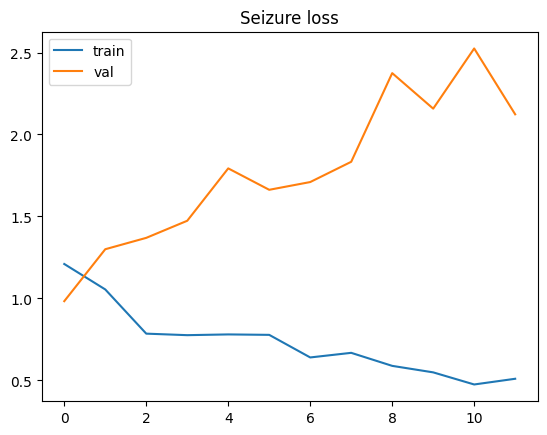

In [9]:
def find_prior_seizure_checkpoint():
    for f in candidates('best_fp32.pth'):
        if f.parent.name=='seizure' and str(OUT) not in str(f):return f
    for f in candidates('NeuroCardioTwin_Deployment.zip'):
        with zipfile.ZipFile(f) as z:
            names=[x for x in z.namelist() if x.endswith('seizure/best_fp32.pth')]
            if names:
                out=CACHE/'old_seizure_fp32.pth';out.write_bytes(z.read(names[0]));return out
    return None

old_ckpt=find_prior_seizure_checkpoint()
print('Previous seizure checkpoint:',old_ckpt or 'NOT FOUND — train from scratch')
model=Classifier().to(DEVICE)
if old_ckpt:
    saved=torch.load(old_ckpt,map_location='cpu',weights_only=True)
    model.load_state_dict(saved['state_dict'],strict=True)
    print('Continuing from previous model weights. Optimizer starts fresh.')
else:
    print('Starting new weights; previous trained weights were not attached.')

# Model is trained for 12 epochs even if initialized from a prior checkpoint.
check('seizure',S,True)
dl=loaders(S)
train_labels=np.array([r[1] for r in S if r[2]=='train'],dtype=int)
n_pos=int(train_labels.sum());n_neg=len(train_labels)-n_pos
pos_weight=min(20.0, max(1.0,n_neg/max(n_pos,1)))
print('positive',n_pos,'negative',n_neg,'pos_weight',pos_weight)
loss_fn=nn.BCEWithLogitsLoss(pos_weight=torch.tensor(pos_weight,device=DEVICE,dtype=torch.float32))
opt=torch.optim.AdamW(model.parameters(),lr=1e-4 if old_ckpt else 2e-4,weight_decay=1e-3)
folder=OUT/'seizure';folder.mkdir(parents=True,exist_ok=True)
history=[];best=float('inf')
for epoch in range(1,EPOCHS+1):
    losses={}
    for sp in ('train','val'):
        model.train(sp=='train');total=0;n=0
        for x,y in dl[sp]:
            x=x.to(DEVICE);y=y.to(DEVICE)
            if sp=='train':opt.zero_grad(set_to_none=True)
            with torch.set_grad_enabled(sp=='train'):
                logits=model(x);loss=loss_fn(logits,y)
                if sp=='train':
                    loss.backward();torch.nn.utils.clip_grad_norm_(model.parameters(),1);opt.step()
            total+=loss.item()*len(y);n+=len(y)
        losses[sp]=total/n
    print('Epoch',epoch,'train',round(losses['train'],4),'val',round(losses['val'],4),flush=True)
    history.append({'epoch':epoch,**losses})
    if losses['val']<best:
        best=losses['val']
        torch.save({'state_dict':model.state_dict(),'name':'seizure','model':'Classifier','epoch':epoch},folder/'best_fp32.pth')
pd.DataFrame(history).to_csv(folder/'history.csv',index=False)
plt.plot([h['train'] for h in history],label='train');plt.plot([h['val'] for h in history],label='val');plt.legend();plt.title('Seizure loss');plt.savefig(folder/'loss.png');plt.show();plt.close()
model.load_state_dict(torch.load(folder/'best_fp32.pth',map_location='cpu',weights_only=True)['state_dict']);model=model.cpu().eval()


Validation-selected F2 threshold: 0.28577300906181335 validation F2: 0.18672199170124482
VALIDATION {
  "threshold": 0.28577300906181335,
  "accuracy": 0.06220095693779904,
  "precision": 0.04390243902439024,
  "recall_sensitivity": 1.0,
  "specificity": 0.02,
  "f1": 0.08411214953271028,
  "f2": 0.18672199170124482,
  "balanced_accuracy": 0.51,
  "auroc": 0.3311111111111111,
  "auprc": 0.03642809419120914,
  "tn": 4,
  "fp": 196,
  "fn": 0,
  "tp": 9
}
HELD-OUT TEST {
  "threshold": 0.28577300906181335,
  "accuracy": 0.3140495867768595,
  "precision": 0.19,
  "recall_sensitivity": 0.9047619047619048,
  "specificity": 0.19,
  "f1": 0.3140495867768595,
  "f2": 0.5163043478260869,
  "balanced_accuracy": 0.5473809523809524,
  "auroc": 0.5695238095238095,
  "auprc": 0.19610177195904502,
  "tn": 38,
  "fp": 162,
  "fn": 4,
  "tp": 38
}


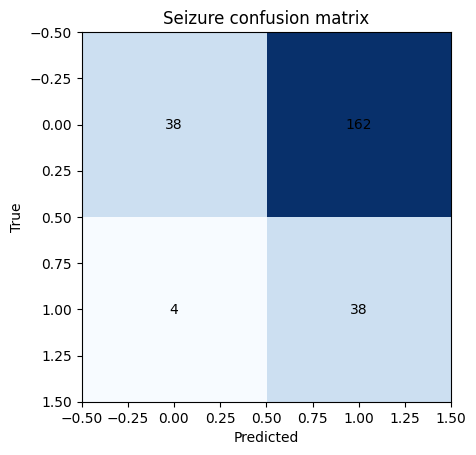

In [10]:
from sklearn.metrics import fbeta_score, precision_recall_curve

def gather(sp):
    yy=[];zz=[]
    with torch.inference_mode():
        for x,y in dl[sp]:
            zz.append(model(x).numpy());yy.append(y.numpy().astype(int))
    truth=np.concatenate(yy);logits=np.concatenate(zz)
    return truth,1/(1+np.exp(-np.clip(logits,-50,50)))

y_val,p_val=gather('val')
# Select threshold on validation only, maximize F2 (recall-focused).
# Includes a range below 0.5, avoiding the all-negative threshold trap.
thresholds=np.unique(np.r_[np.linspace(.01,.99,199),p_val])
thresholds=thresholds[(thresholds>0)&(thresholds<1)]
scores=np.array([fbeta_score(y_val,p_val>=t,beta=2,zero_division=0) for t in thresholds])
best_score=float(scores.max())
# Among tied scores, choose the largest threshold to avoid unnecessary false alarms.
chosen=float(thresholds[np.flatnonzero(np.isclose(scores,best_score))[-1]])
print('Validation-selected F2 threshold:',chosen,'validation F2:',best_score)

from sklearn.metrics import f1_score,precision_score,recall_score

def metrics(y,p,t):
    yh=(p>=t).astype(int);tn,fp,fn,tp=confusion_matrix(y,yh,labels=[0,1]).ravel()
    return {'threshold':float(t),'accuracy':float(accuracy_score(y,yh)),
        'precision':float(precision_score(y,yh,zero_division=0)),
        'recall_sensitivity':float(recall_score(y,yh,zero_division=0)),
        'specificity':float(tn/max(tn+fp,1)),
        'f1':float(f1_score(y,yh,zero_division=0)),
        'f2':float(fbeta_score(y,yh,beta=2,zero_division=0)),
        'balanced_accuracy':float(balanced_accuracy_score(y,yh)),
        'auroc':float(roc_auc_score(y,p)), 'auprc':float(average_precision_score(y,p)),
        'tn':int(tn),'fp':int(fp),'fn':int(fn),'tp':int(tp)}

val_report=metrics(y_val,p_val,chosen)
y_test,p_test=gather('test')
test_report=metrics(y_test,p_test,chosen)
print('VALIDATION',json.dumps(val_report,indent=2))
print('HELD-OUT TEST',json.dumps(test_report,indent=2))
(folder/'metrics.json').write_text(json.dumps({'validation':val_report,'test':test_report},indent=2))
pd.DataFrame([test_report]).to_csv(folder/'test_metrics.csv',index=False)
cm=confusion_matrix(y_test,p_test>=chosen,labels=[0,1]);plt.imshow(cm,cmap='Blues');plt.title('Seizure confusion matrix');plt.xlabel('Predicted');plt.ylabel('True')
for (i,j),v in np.ndenumerate(cm):plt.text(j,i,str(v),ha='center',va='center')
plt.savefig(folder/'confusion.png');plt.show();plt.close()


## Export FP32 + selected-head INT8; preserve available old arrhythmia / forecasting outputs

In [11]:
from torch.ao.quantization import quantize_dynamic
quant=Classifier().cpu().eval();quant.load_state_dict(model.state_dict())
quant.head=quantize_dynamic(quant.head,{nn.Linear},dtype=torch.qint8)
torch.save({'state_dict':quant.state_dict(),'model':'Classifier','quantized_head':True},folder/'head_int8.pth')
with torch.inference_mode():
    x=torch.zeros(1,1,LENGTH)
    reload_fp=Classifier().eval();reload_fp.load_state_dict(torch.load(folder/'best_fp32.pth',map_location='cpu',weights_only=True)['state_dict']);reload_fp(x)
    reload_int=Classifier().eval();reload_int.head=quantize_dynamic(reload_int.head,{nn.Linear},dtype=torch.qint8)
    reload_int.load_state_dict(torch.load(folder/'head_int8.pth',map_location='cpu',weights_only=True)['state_dict']);reload_int(x)
print('FP32 and head-INT8 reload OK')
config={'fs':FS,'context_seconds':CTX,'seed':SEED,'epochs':EPOCHS,'seizure_threshold':chosen,'task':'seizure_detection','preprocessing':'resample and window-wise robust scale; use identical transform at inference'}
(OUT/'config.json').write_text(json.dumps(config,indent=2))
# Extract optional previous deployment files (only the other 2 tasks) for a combined zip.
archives=candidates('NeuroCardioTwin_Deployment.zip')
if archives:
    with zipfile.ZipFile(archives[0]) as z:
        for name in z.namelist():
            if name.startswith(('arrhythmia/','forecast/')) and not name.endswith('/'):
                dest=OUT/name;dest.parent.mkdir(parents=True,exist_ok=True);dest.write_bytes(z.read(name))
    print('Copied previous arrhythmia + forecast files (not retrained).')
else:print('Old deployment package not attached: export includes repaired seizure only.')
# Exact architecture source copied from the original notebook model definition.
model_src='import torch\nfrom torch import nn\nFUTURE=128\nclass Encoder(nn.Module):\n    def __init__(self,channels=1,d=48):\n        super().__init__();self.cnn=nn.Sequential(nn.Conv1d(channels,d,9,4,4),nn.GELU(),nn.Conv1d(d,d,7,4,3),nn.GELU())\n        self.pos=nn.Parameter(torch.randn(1,32,d)*.01)\n        layer=nn.TransformerEncoderLayer(d,4,96,dropout=.1,batch_first=True,norm_first=True)\n        self.blocks=nn.TransformerEncoder(layer,2,enable_nested_tensor=False)\n    def forward(self,x):\n        z=self.cnn(x).transpose(1,2);return self.blocks(z+self.pos[:,:z.size(1)]).mean(1)\nclass Classifier(nn.Module):\n    def __init__(self):super().__init__();self.enc=Encoder(1);self.head=nn.Linear(48,1)\n    def forward(self,x):return self.head(self.enc(x)).squeeze(-1)\nclass Forecast(nn.Module):\n    def __init__(self):\n        super().__init__();self.ecg=Encoder(1);self.eeg=Encoder(1)\n        self.quality=nn.Sequential(nn.Linear(4,16),nn.ReLU(),nn.Linear(16,2),nn.Sigmoid())\n        self.head=nn.Linear(96,2*FUTURE)\n    def forward(self,x):\n        stats=torch.stack((x.mean(-1),x.std(-1)),dim=-1).flatten(1)\n        w=self.quality(stats);a=self.ecg(x[:,0:1])*w[:,0:1];b=self.eeg(x[:,1:2])*w[:,1:2]\n        return self.head(torch.cat((a,b),-1)).view(-1,2,FUTURE),w\n'
# model_src is the literal repr of the original write_text argument.
# Parse literal safely using ast.literal_eval, no eval.
import ast
(OUT/'neurocardiotwin_models.py').write_text(model_src)
(OUT/'local_inference.py').write_text("""import argparse, json, numpy as np, torch
from torch import nn
from pathlib import Path
from neurocardiotwin_models import Classifier
from torch.ao.quantization import quantize_dynamic
p=argparse.ArgumentParser();p.add_argument('--root',default='.');p.add_argument('--npz',required=True);p.add_argument('--int8',action='store_true');a=p.parse_args()
root=Path(a.root);cfg=json.loads((root/'config.json').read_text())
model=Classifier().eval()
if a.int8:model.head=quantize_dynamic(model.head,{nn.Linear},dtype=torch.qint8)
ck=torch.load(root/'seizure'/('head_int8.pth' if a.int8 else 'best_fp32.pth'),map_location='cpu',weights_only=True)
model.load_state_dict(ck['state_dict'])
x=np.load(a.npz)['x'].astype('float32');assert x.shape==(1,512),x.shape
with torch.inference_mode():p=float(torch.sigmoid(model(torch.from_numpy(x)[None])).item())
print({'probability':p,'threshold':cfg['seizure_threshold'],'detected':p>=cfg['seizure_threshold']})
""")
zip_path=Path('/kaggle/working/NeuroCardioTwin_Seizure_Repaired_Deployment.zip')
with zipfile.ZipFile(zip_path,'w',zipfile.ZIP_DEFLATED) as z:
    for f in OUT.rglob('*'):
        if f.is_file():z.write(f,f.relative_to(OUT))
print('DOWNLOAD FROM KAGGLE OUTPUT:',zip_path)
print('ALSO DOWNLOAD (if newly created): /kaggle/working/NeuroCardioTwin_CHB_Cache.zip')


FP32 and head-INT8 reload OK
Old deployment package not attached: export includes repaired seizure only.
DOWNLOAD FROM KAGGLE OUTPUT: /kaggle/working/NeuroCardioTwin_Seizure_Repaired_Deployment.zip
ALSO DOWNLOAD (if newly created): /kaggle/working/NeuroCardioTwin_CHB_Cache.zip


/tmp/ipykernel_23/609311974.py:3: DeprecationWarning: torch.ao.quantization is deprecated and will be removed in 2.10. 
For migrations of users: 
1. Eager mode quantization (torch.ao.quantization.quantize, torch.ao.quantization.quantize_dynamic), please migrate to use torchao eager mode quantize_ API instead 
2. FX graph mode quantization (torch.ao.quantization.quantize_fx.prepare_fx,torch.ao.quantization.quantize_fx.convert_fx, please migrate to use torchao pt2e quantization API instead (prepare_pt2e, convert_pt2e) 
3. pt2e quantization has been migrated to torchao (https://github.com/pytorch/ao/tree/main/torchao/quantization/pt2e) 
see https://github.com/pytorch/ao/issues/2259 for more details
  quant.head=quantize_dynamic(quant.head,{nn.Linear},dtype=torch.qint8)
/tmp/ipykernel_23/609311974.py:8: DeprecationWarning: torch.ao.quantization is deprecated and will be removed in 2.10. 
For migrations of users: 
1. Eager mode quantization (torch.ao.quantization.quantize, torch.ao.quantiza